# 04 · Modelling — PCOS Classification

Implements the five classifiers required by the assignment on the **same** data, tunes each with cross-validation on the **training set only**, and evaluates once on the held-out test set.

| # | Model |
|---|---|
| 1 | Logistic Regression |
| 2 | Decision Tree |
| 3 | K-Nearest Neighbours |
| 4 | Naive Bayes (Gaussian) |
| 5 | Support Vector Machine |

**Metrics (per model):** Accuracy · AUC · Precision · Recall · F1 · MCC

**Design**
- Every model is a `Pipeline(preprocessor → classifier)`, so the saved `.joblib` takes a *raw* cleaned CSV row and needs no separate scaling step.
- Tuning: `GridSearchCV`, stratified 5-fold CV on `train.csv`, optimising **ROC-AUC** (threshold-free, robust to the 2:1 imbalance).
- The test set is touched only for the final scoring — never for tuning.

## 1. Setup & load data

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, confusion_matrix, roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", "{:,.4f}".format)

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"; MODEL_DIR = ROOT / "model"
TARGET, RS = "pcos", 26

train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
test = pd.read_csv(ROOT / "test_data.csv")
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
preprocessor = joblib.load(MODEL_DIR / "preprocessor.joblib")      # unfitted-state is irrelevant: we clone it per model

print(f"train {X_train.shape} | test {X_test.shape} | PCOS share train {y_train.mean():.1%}, test {y_test.mean():.1%}")
assert list(X_train.columns) == list(X_test.columns)

train (432, 41) | test (109, 41) | PCOS share train 32.6%, test 33.0%


## 2. Baseline: the five models with default settings
A reference point, so we can tell whether tuning actually helps. 5-fold stratified CV AUC on the training set.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def make_pipe(clf):
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RS),
    "Decision Tree": DecisionTreeClassifier(random_state=RS),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(probability=True, random_state=RS),
}
rows = []
for name, clf in base_models.items():
    s = cross_val_score(make_pipe(clf), X_train, y_train, cv=cv, scoring="roc_auc")
    rows.append({"model": name, "cv_auc_mean": s.mean(), "cv_auc_std": s.std()})
baseline = pd.DataFrame(rows).set_index("model"); baseline

,cv_auc_mean,cv_auc_std
model,,
Logistic Regression,0.9279,0.0302
Decision Tree,0.8444,0.0492
KNN,0.8575,0.0376
Naive Bayes,0.9013,0.0357
SVM,0.9333,0.0318


## 3. Hyper-parameter tuning
Grids are kept modest (the dataset has only 432 training rows, so a huge search would mostly overfit the CV folds).

| Model | Parameters searched |
|---|---|
| Logistic Regression | `C`, `penalty` (L1/L2), `class_weight` |
| Decision Tree | `max_depth`, `min_samples_leaf`, `min_samples_split`, `criterion`, `class_weight` |
| KNN | `n_neighbors`, `weights`, `p` (Manhattan/Euclidean) |
| Naive Bayes | `var_smoothing` |
| SVM | `C`, `gamma`, `kernel`, `class_weight` |

In [3]:
grids = {
    "Logistic Regression": (LogisticRegression(solver="liblinear", max_iter=5000, random_state=RS),
        {"clf__C": [0.01, 0.1, 0.5, 1, 5, 10, 50], "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RS),
        {"clf__max_depth": [3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 3, 5, 10],
         "clf__min_samples_split": [2, 5, 10], "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
    "Naive Bayes": (GaussianNB(),
        {"clf__var_smoothing": np.logspace(-11, -1, 11)}),
    "SVM": (SVC(probability=True, random_state=RS),
        {"clf__C": [0.1, 0.5, 1, 5, 10, 50], "clf__gamma": ["scale", 0.001, 0.01, 0.05, 0.1],
         "clf__kernel": ["rbf", "linear"], "clf__class_weight": [None, "balanced"]}),
}
searches, tune_rows = {}, []
for name, (clf, grid) in grids.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    tune_rows.append({"model": name, "combos": len(gs.cv_results_["params"]), "best_cv_auc": gs.best_score_,
                      "baseline_cv_auc": baseline.loc[name, "cv_auc_mean"],
                      "best_params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                      "secs": round(time.time() - t0, 1)})
tuning = pd.DataFrame(tune_rows).set_index("model")
tuning["gain"] = tuning["best_cv_auc"] - tuning["baseline_cv_auc"]
pd.set_option("display.max_colwidth", 120); tuning

,combos,best_cv_auc,baseline_cv_auc,best_params,secs,gain
model,,,,,,
Logistic Regression,28,0.9398,0.9279,"{'C': 0.5, 'class_weight': None, 'penalty': 'l1'}",3.7000,0.0119
Decision Tree,288,0.8958,0.8444,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}",5.6000,0.0514
KNN,28,0.9304,0.8575,"{'n_neighbors': 21, 'p': 1, 'weights': 'distance'}",0.6000,0.0730
Naive Bayes,11,0.9311,0.9013,{'var_smoothing': 0.1},0.2000,0.0298
SVM,120,0.9390,0.9333,"{'C': 0.5, 'class_weight': 'balanced', 'gamma': 0.01, 'kernel': 'rbf'}",9.4000,0.0058


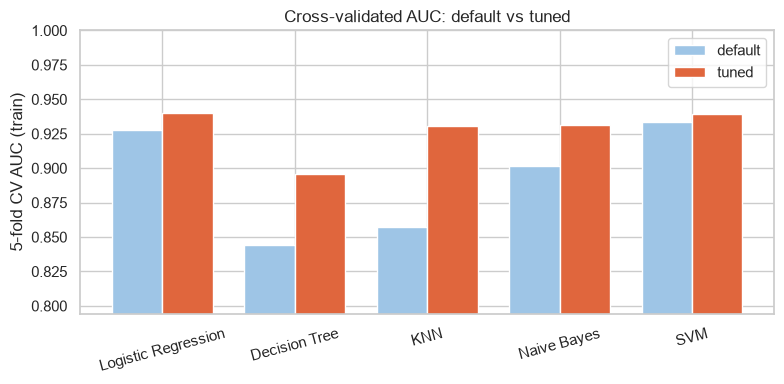

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
idx = np.arange(len(tuning)); w = .38
ax.bar(idx - w/2, tuning.baseline_cv_auc, w, label="default", color="#9ec5e6")
ax.bar(idx + w/2, tuning.best_cv_auc, w, label="tuned", color="#e0663d")
ax.set_xticks(idx); ax.set_xticklabels(tuning.index, rotation=15); ax.set_ylabel("5-fold CV AUC (train)")
ax.set_ylim(tuning.baseline_cv_auc.min() - .05, 1.0); ax.legend(); ax.set_title("Cross-validated AUC: default vs tuned")
plt.tight_layout(); plt.savefig(FIG / "19_tuning_gain.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Final evaluation on the held-out test set
Each tuned pipeline was already refit on the whole training set by `GridSearchCV`. The test set is scored once.

In [5]:
def evaluate(model, X, y):
    pred = model.predict(X); proba = model.predict_proba(X)[:, 1]
    return {"Accuracy": accuracy_score(y, pred), "AUC": roc_auc_score(y, proba), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "MCC": matthews_corrcoef(y, pred)}

final = {n: s.best_estimator_ for n, s in searches.items()}
results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in final.items()}).T
results.index.name = "ML Model Name"
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9174,0.9536,0.8649,0.8889,0.8767,0.8148
Decision Tree,0.8257,0.8579,0.7179,0.7778,0.7467,0.6153
KNN,0.8624,0.9547,0.9565,0.6111,0.7458,0.6886
Naive Bayes,0.8532,0.9433,0.7500,0.8333,0.7895,0.6795
SVM,0.8257,0.9384,0.6809,0.8889,0.7711,0.6490


In [6]:
# train-vs-test gap -> overfitting check
tr_res = pd.DataFrame({n: evaluate(m, X_train, y_train) for n, m in final.items()}).T
gap = pd.DataFrame({"train_AUC": tr_res.AUC, "test_AUC": results.AUC, "train_Acc": tr_res.Accuracy, "test_Acc": results.Accuracy})
gap["Acc_gap"] = gap.train_Acc - gap.test_Acc
gap

,train_AUC,test_AUC,train_Acc,test_Acc,Acc_gap
Logistic Regression,0.9661,0.9536,0.9213,0.9174,0.0039
Decision Tree,0.9690,0.8579,0.9051,0.8257,0.0794
KNN,1.0000,0.9547,1.0000,0.8624,0.1376
Naive Bayes,0.9505,0.9433,0.8773,0.8532,0.0241
SVM,0.9671,0.9384,0.9144,0.8257,0.0887


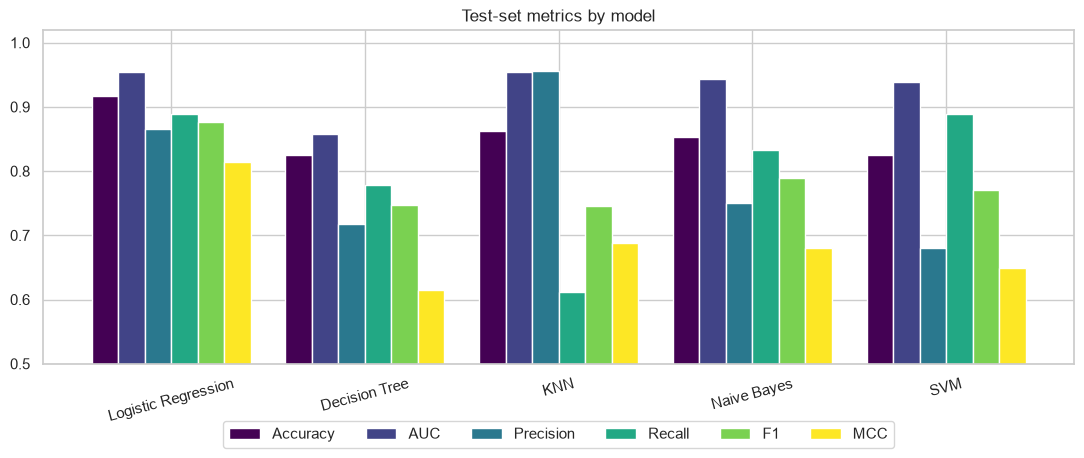

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
results.plot(kind="bar", ax=ax, width=.82, colormap="viridis")
ax.set_ylim(0.5, 1.02); ax.set_title("Test-set metrics by model"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(.5, -.15))
plt.tight_layout(); plt.savefig(FIG / "20_test_metrics_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.1 Confusion matrices

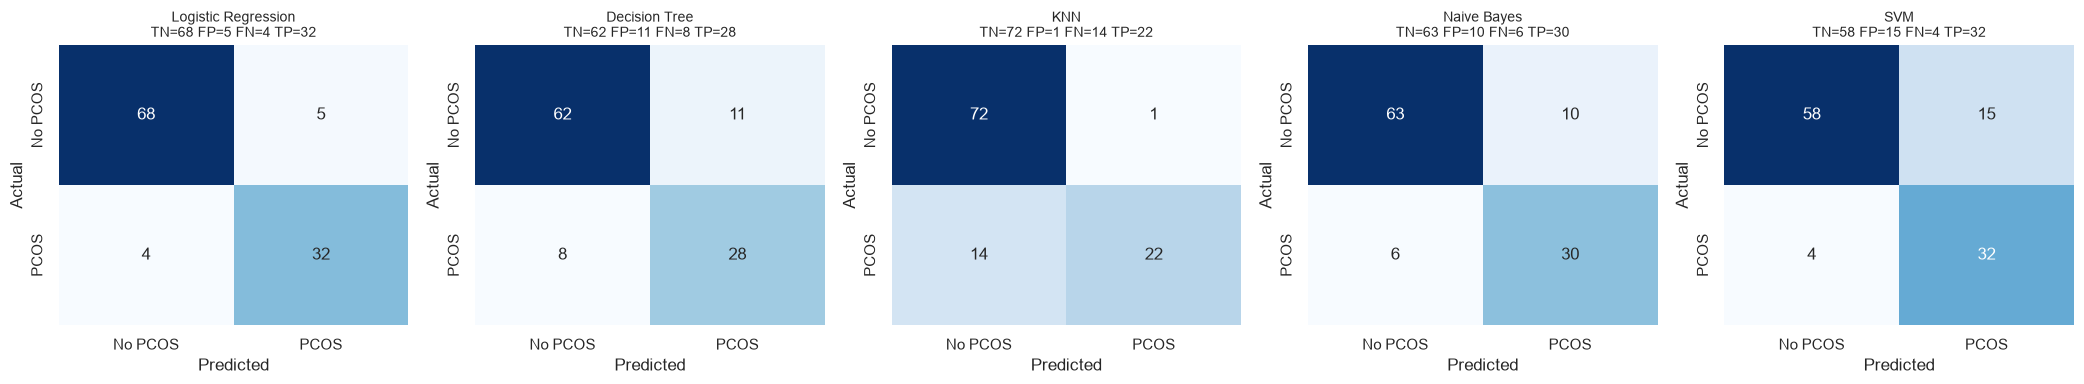

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4))
for ax, (n, m) in zip(axes, final.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No PCOS", "PCOS"], yticklabels=["No PCOS", "PCOS"])
    ax.set_title(f"{n}\nTN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}", fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "21_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.2 ROC curves

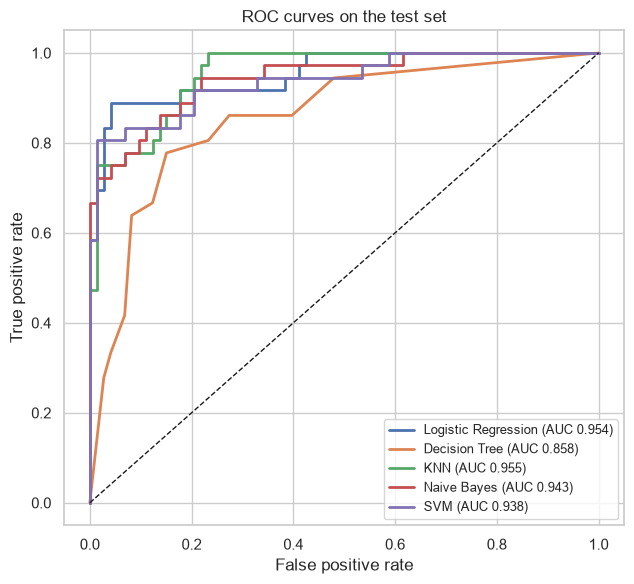

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for n, m in final.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, lw=2, label=f"{n} (AUC {results.loc[n, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "22_roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.3 Classification reports

In [10]:
for n, m in final.items():
    print(f"===== {n} ====="); print(classification_report(y_test, m.predict(X_test), target_names=["No PCOS", "PCOS"], digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

     No PCOS      0.944     0.932     0.938        73
        PCOS      0.865     0.889     0.877        36

    accuracy                          0.917       109
   macro avg      0.905     0.910     0.907       109
weighted avg      0.918     0.917     0.918       109

===== Decision Tree =====
              precision    recall  f1-score   support

     No PCOS      0.886     0.849     0.867        73
        PCOS      0.718     0.778     0.747        36

    accuracy                          0.826       109
   macro avg      0.802     0.814     0.807       109
weighted avg      0.830     0.826     0.827       109

===== KNN =====
              precision    recall  f1-score   support

     No PCOS      0.837     0.986     0.906        73
        PCOS      0.957     0.611     0.746        36

    accuracy                          0.862       109
   macro avg      0.897     0.799     0.826       109


## 5. Stability check
With only 109 test rows, one split can flatter or punish a model by a few points. We repeat the evaluation with 5×5 repeated stratified CV **on the full data** (refitting the tuned pipeline each time, preprocessing included) to see whether the ranking holds.

In [11]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
full_X = pd.concat([X_train, X_test]); full_y = pd.concat([y_train, y_test])
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
scoring = {"Accuracy": "accuracy", "AUC": "roc_auc", "F1": "f1", "MCC": make_scorer} if False else           {"Accuracy": "accuracy", "AUC": "roc_auc", "F1": "f1"}
rows = {}
for n, gs in searches.items():
    cvr = cross_validate(clone(gs.best_estimator_), full_X, full_y, cv=rcv, scoring=scoring, n_jobs=-1)
    rows[n] = {f"{k}_mean": cvr[f"test_{k}"].mean() for k in scoring} | {"AUC_std": cvr["test_AUC"].std()}
stability = pd.DataFrame(rows).T; stability.index.name = "model"
print("(note: hyper-parameters were chosen on the train rows, so this is slightly optimistic; use it for RANKING stability)")
stability

(note: hyper-parameters were chosen on the train rows, so this is slightly optimistic; use it for RANKING stability)


,Accuracy_mean,AUC_mean,F1_mean,AUC_std
model,,,,
Logistic Regression,0.8909,0.9448,0.8280,0.0223
Decision Tree,0.8533,0.8757,0.7670,0.0399
KNN,0.8416,0.9335,0.6930,0.0223
Naive Bayes,0.8564,0.9357,0.7885,0.0188
SVM,0.8724,0.9413,0.8107,0.0205


## 6. Feature importance (what drives the best models)

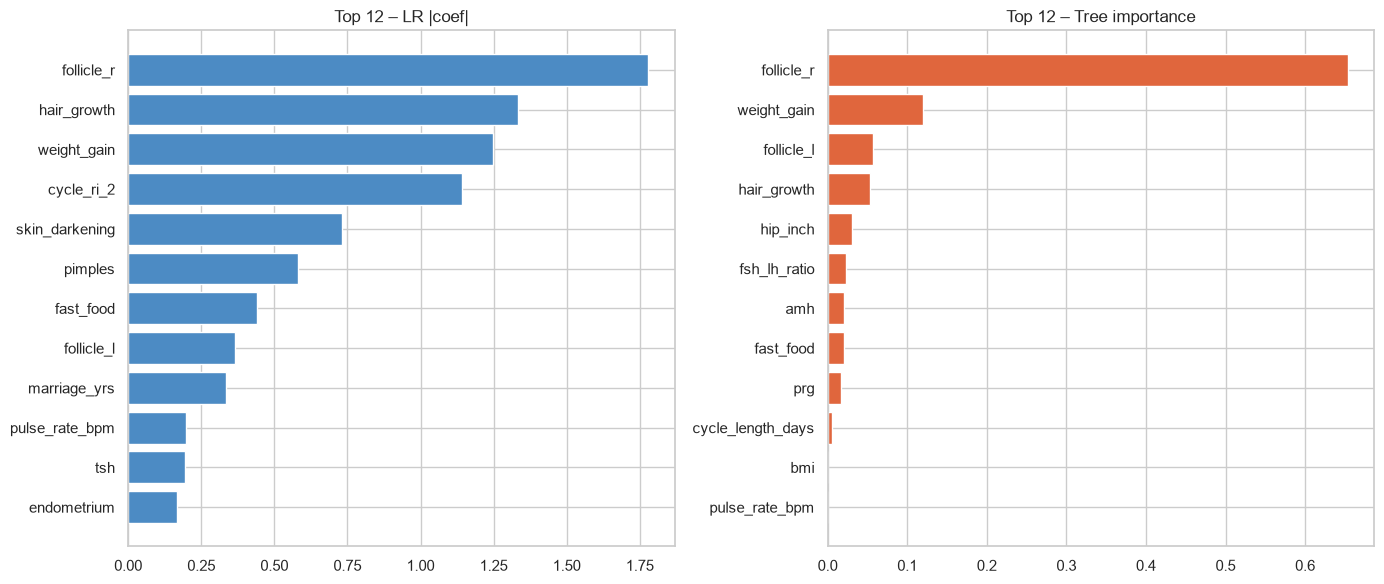

,LR |coef|,Tree importance
follicle_r,1.7797,0.6539
weight_gain,1.2485,0.1199
follicle_l,0.3653,0.0565
hair_growth,1.3339,0.0532
hip_inch,0.0000,0.0305
fsh_lh_ratio,0.0000,0.0232
amh,0.0620,0.0202
fast_food,0.4391,0.0202
prg,0.0737,0.0172
cycle_length_days,0.0545,0.0051


In [12]:
feat_names = final["Logistic Regression"].named_steps["prep"].get_feature_names_out()
lr = final["Logistic Regression"].named_steps["clf"]; dt = final["Decision Tree"].named_steps["clf"]
imp = pd.DataFrame({"LR |coef|": np.abs(lr.coef_[0]), "Tree importance": dt.feature_importances_}, index=feat_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, colr in zip(axes, imp.columns, ["#4c8bc4", "#e0663d"]):
    top = imp[col].sort_values().tail(12)
    ax.barh(top.index, top.values, color=colr); ax.set_title(f"Top 12 – {col}")
plt.tight_layout(); plt.savefig(FIG / "23_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
imp.sort_values("Tree importance", ascending=False).head(10)

## 7. Save models & results
Each file is a **complete pipeline** (preprocessing + classifier). The Streamlit app loads these and calls `.predict` / `.predict_proba` on the raw uploaded CSV — **nothing is retrained**.

In [13]:
FILES = {"Logistic Regression": "logistic_regression.joblib", "Decision Tree": "decision_tree.joblib",
         "KNN": "knn.joblib", "Naive Bayes": "naive_bayes.joblib", "SVM": "svm.joblib"}
for n, f in FILES.items():
    joblib.dump(final[n], MODEL_DIR / f)

results.round(4).to_csv(ROOT / "reports" / "model_metrics.csv")
tuning.drop(columns="secs").assign(best_params=tuning.best_params.astype(str)).to_csv(ROOT / "reports" / "tuning_summary.csv")

# reload every saved model from disk and confirm it reproduces the same test metrics
chk = pd.DataFrame({n: evaluate(joblib.load(MODEL_DIR / f), X_test, y_test) for n, f in FILES.items()}).T
pd.testing.assert_frame_equal(chk, results[chk.columns], check_names=False, check_exact=False, rtol=1e-9)
print("✅ all 5 models reload from disk and reproduce identical test metrics\n")
for f in FILES.values(): print(f"  model/{f:28s}{(MODEL_DIR/f).stat().st_size/1024:8.1f} KB")

✅ all 5 models reload from disk and reproduce identical test metrics

  model/logistic_regression.joblib      11.1 KB
  model/decision_tree.joblib            13.1 KB
  model/knn.joblib                     182.8 KB
  model/naive_bayes.joblib              12.2 KB
  model/svm.joblib                     122.7 KB


## 8. Final comparison table

In [14]:
best_by = results.rank(ascending=False).mean(axis=1).sort_values()
display(results.round(4))
print("Average rank across the 6 metrics (lower = better):"); print(best_by.round(2).to_string())
print(f"\n🏆 Best overall on this test set: {best_by.index[0]}")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9174,0.9536,0.8649,0.8889,0.8767,0.8148
Decision Tree,0.8257,0.8579,0.7179,0.7778,0.7467,0.6153
KNN,0.8624,0.9547,0.9565,0.6111,0.7458,0.6886
Naive Bayes,0.8532,0.9433,0.7500,0.8333,0.7895,0.6795
SVM,0.8257,0.9384,0.6809,0.8889,0.7711,0.6490


Average rank across the 6 metrics (lower = better):
ML Model Name
Logistic Regression   1.4200
KNN                   2.6700
Naive Bayes           2.8300
SVM                   3.6700
Decision Tree         4.4200

🏆 Best overall on this test set: Logistic Regression
